# Basin Hexagon Vegetation Summary

Build hexagon feature classes at a user-selected flat-to-flat size and summarize the real threshold rasters into each hex. Outputs include basin overlap and membership, CWHR vegetation-type percentages, TRPA reporting type percentages (JP, SMC, RF, per the threshold report's Table 1), early/mid/late seral percentages, and stand-density attainment percentages.

This notebook uses the configured basin boundary and threshold geodatabase rasters. Percentages use valid raster area as the denominator, so NoData is excluded. Hexes are not clipped; `basin_pct` records overlap and `in_basin` means the hex centroid is inside the boundary. No sampling, allocation, or GRTS logic.

## 1. Inputs and Size

Set `HEX_SIZE_HA` to the area of each hexagon in hectares. The boundary, vegetation type, seral stage, and density rasters come from `config.yaml`.

In [61]:
from pathlib import Path
import re
import shutil
import tempfile
import time
import uuid

import arcpy
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

with (ROOT / "config.yaml").open(encoding="utf-8") as stream:
    CFG = yaml.safe_load(stream)


def configured_source(entry, preferred=None):
    """Choose the configured source form without importing the larger design package."""
    if not isinstance(entry, dict):
        return str(entry)
    source_form = entry.get("use") or preferred
    if source_form and entry.get(source_form):
        return str(entry[source_form])
    for source_form in ("rrk", "sde", "rest", "file", "lidar"):
        if entry.get(source_form):
            return str(entry[source_form])
    raise ValueError(f"No usable source configured: {entry}")


HEX_SIZE_HA = 100.0
WORKING_CRS = arcpy.SpatialReference(int(CFG["crs"]["working"].split(":")[-1]))

# Scratch work happens outside the repo, in the OS temp folder: this repo lives under
# Documents, which OneDrive's "PC folder backup" syncs in the background, and it
# intermittently locks or marks read-only a file geodatabase that ArcPy is actively
# writing hundreds of scratch tables into. Every "cannot open" / "Cannot create output" /
# "Workspace or data source is read only" error traced back to that conflict, not to arcpy.
OUTPUT_GDB = Path(tempfile.gettempdir()) / "forest_health_hex_scratch" / "vegetation_hexes_output.gdb"
FINAL_OUTPUT_DIR = ROOT / CFG["paths"]["outputs"]

BOUNDARY_SOURCE = configured_source(CFG["sources"]["boundary"])
VEG_TYPE_RASTER = configured_source(CFG["sources"]["veg_type"], preferred="rrk")
SERAL_RASTER = configured_source(CFG["sources"]["rrk_seral"], preferred="rrk")
DENSITY_RASTER = configured_source(CFG["sources"]["rrk_density_assessment"], preferred="rrk")
TPA_RASTER = configured_source(CFG["sources"]["rrk_tpa"], preferred="rrk")
BASAL_AREA_RASTER = configured_source(CFG["sources"]["rrk_ba"], preferred="rrk")

# Report Table 1: CWHR WHRTYPE to the three assessed TRPA forest types (JP, SMC, RF).
WHR_TO_TRPA_TYPE = CFG["tessellation"]["whr_to_type"]

arcpy.CheckOutExtension("Spatial")
arcpy.env.overwriteOutput = True

## 2. Hex Geometry and Basin Membership

Create full hexagons that intersect the basin. `IN_BASIN` tests the hex centroid; `BASIN_PCT` is the share of the hex area inside the boundary.

In [47]:
def ensure_output_gdb():
    OUTPUT_GDB.parent.mkdir(parents=True, exist_ok=True)
    if not arcpy.Exists(str(OUTPUT_GDB)):
        arcpy.management.CreateFileGDB(str(OUTPUT_GDB.parent), OUTPUT_GDB.name)


def prepare_basin(boundary_source=BOUNDARY_SOURCE):
    """Copy the boundary and project it only when its CRS differs from the working CRS."""
    ensure_output_gdb()
    source = str(boundary_source)
    if not source.lower().startswith("http") and not Path(source).is_absolute():
        source = str(ROOT / source)

    # Unique scratch name, not delete-then-recreate: this file geodatabase's workspace
    # cache can refuse to create an output over a name it just deleted.
    copied = arcpy.CreateUniqueName("basin_source", str(OUTPUT_GDB))
    arcpy.management.CopyFeatures(source, copied)
    if int(arcpy.management.GetCount(copied)[0]) == 0:
        raise RuntimeError(f"Boundary source contains no features: {source}")

    source_crs = arcpy.Describe(copied).spatialReference
    if source_crs.factoryCode == WORKING_CRS.factoryCode:
        return copied

    basin_fc = arcpy.CreateUniqueName("basin_boundary", str(OUTPUT_GDB))
    arcpy.management.Project(copied, basin_fc, WORKING_CRS)
    if not arcpy.Exists(basin_fc) or int(arcpy.management.GetCount(basin_fc)[0]) == 0:
        raise RuntimeError(
            f"Project did not create a non-empty basin layer: {basin_fc}\n{arcpy.GetMessages()}"
        )
    return basin_fc


def create_hex_grid(hex_size_ha, basin_fc, output_name="vegetation_hexes"):
    """Create full hexagons of the requested area that intersect the basin."""
    if hex_size_ha <= 0:
        raise ValueError("hex_size_ha must be greater than zero")
    if not arcpy.Exists(basin_fc):
        raise FileNotFoundError(f"Basin feature class does not exist: {basin_fc}")
    ensure_output_gdb()

    extent = arcpy.Describe(basin_fc).extent
    hex_area_m2 = float(hex_size_ha) * 10_000.0
    flat_to_flat_m = np.sqrt(2.0 * hex_area_m2 / np.sqrt(3.0))
    grid_extent = arcpy.Extent(
        extent.XMin - flat_to_flat_m, extent.YMin - flat_to_flat_m,
        extent.XMax + flat_to_flat_m, extent.YMax + flat_to_flat_m,
        spatial_reference=WORKING_CRS,
    )
    raw_fc = arcpy.CreateUniqueName(f"{output_name}_all", str(OUTPUT_GDB))
    output_fc = arcpy.CreateUniqueName(output_name, str(OUTPUT_GDB))

    arcpy.management.GenerateTessellation(
        raw_fc, grid_extent, "HEXAGON", f"{float(hex_size_ha)} Hectares", WORKING_CRS
    )
    layer_name = f"hex_candidates_{Path(output_fc).name}"
    arcpy.management.MakeFeatureLayer(raw_fc, layer_name)
    arcpy.management.SelectLayerByLocation(layer_name, "INTERSECT", basin_fc)
    arcpy.management.CopyFeatures(layer_name, output_fc)
    arcpy.management.Delete(layer_name)

    arcpy.management.AddField(output_fc, "HEX_ID", "LONG")
    with arcpy.da.UpdateCursor(output_fc, ["OID@", "HEX_ID"]) as rows:
        for row in rows:
            row[1] = row[0]
            rows.updateRow(row)
    return output_fc


def add_basin_membership(hex_fc, basin_fc):
    """Add centroid membership and percent of each hex covered by the basin."""
    arcpy.management.AddField(hex_fc, "IN_BASIN", "SHORT")
    arcpy.management.AddField(hex_fc, "BASIN_PCT", "DOUBLE")
    basin = None
    with arcpy.da.SearchCursor(basin_fc, ["SHAPE@"]) as rows:
        for (shape,) in rows:
            basin = shape if basin is None else basin.union(shape)
    if basin is None:
        raise ValueError(f"Basin layer has no geometry: {basin_fc}")

    with arcpy.da.UpdateCursor(hex_fc, ["SHAPE@", "IN_BASIN", "BASIN_PCT"]) as rows:
        for row in rows:
            shape = row[0]
            center = arcpy.PointGeometry(shape.trueCentroid, WORKING_CRS)
            fraction = shape.intersect(basin, 4).area / shape.area
            row[1] = int(basin.contains(center))
            row[2] = min(100.0, max(0.0, 100.0 * fraction))
            rows.updateRow(row)


## 3. Vegetation, Seral, and Density Attributes

The same zonal-area function handles each categorical raster. For every hex, class percentages sum to 100 across that raster's valid pixels; NoData is not counted. `TRPA_jp_pct`, `TRPA_smc_pct`, and `TRPA_rf_pct` regroup the CWHR percentages into the report's Table 1 forest types, each as a share of `TRPA_frame_pct` (the assessed conifer frame's share of the hex, not of total land); `TRPA_type` is the dominant of the three. The density attributes also include mean trees per acre and mean basal area per acre.

In [62]:
def read_rows(table_path, fields, attempts=5, delay_s=1.0):
    """Read every row from a table or feature class just created by a geoprocessing tool.

    The file geodatabase workspace cache can report a table ArcPy itself just wrote as
    unreadable ("cannot open ...") until the cache is cleared; this happens on
    TabulateArea, ZonalStatisticsAsTable, and other tool outputs unpredictably, not on a
    fixed subset. Retry with a cache clear instead of guessing which call sites need it.
    """
    workspace = str(Path(table_path).parent)
    last_error = None
    for _ in range(attempts):
        try:
            with arcpy.da.SearchCursor(table_path, fields) as rows:
                return [tuple(row) for row in rows]
        except RuntimeError as error:
            last_error = error
            arcpy.management.ClearWorkspaceCache(workspace)
            time.sleep(delay_s)
    raise RuntimeError(f"Could not open {table_path} after {attempts} attempts") from last_error


def add_class_percentages(hex_fc, raster_path, class_field, field_prefix, labels=None):
    """Add one percentage field per raster class, normalizing over non-NoData area."""
    labels = labels or {}
    raster = arcpy.Raster(raster_path)
    raster_sr = arcpy.Describe(raster_path).spatialReference
    # Unique scratch names, not delete-then-recreate: this file geodatabase's workspace
    # cache can refuse to create an output over a name it just deleted, so never reuse one.
    zones = arcpy.CreateUniqueName(f"zones_{field_prefix.lower()}", str(OUTPUT_GDB))
    area_table = arcpy.CreateUniqueName(f"area_{field_prefix.lower()}", str(OUTPUT_GDB))

    arcpy.management.Project(hex_fc, zones, raster_sr)
    arcpy.sa.TabulateArea(
        zones, "HEX_ID", raster_path, class_field, area_table, raster.meanCellWidth
    )
    area_fields = [
        field.name for field in arcpy.ListFields(area_table)
        if field.type not in ("OID", "Geometry") and field.name.upper() != "HEX_ID"
    ]
    if not area_fields:
        raise ValueError(f"No raster classes found for {raster_path}")

    records = read_rows(area_table, ["HEX_ID"] + area_fields)
    areas = pd.DataFrame.from_records(records, columns=["HEX_ID"] + area_fields).set_index("HEX_ID")
    areas = areas.apply(pd.to_numeric, errors="coerce").fillna(0.0)
    totals = areas.sum(axis=1).replace(0, np.nan)
    percentages = areas.div(totals, axis=0) * 100.0

    field_map = {}
    existing = {field.name.upper() for field in arcpy.ListFields(hex_fc)}
    for source_field in area_fields:
        class_code = source_field
        for prefix in (f"{class_field}_", "VALUE_"):
            if class_code.upper().startswith(prefix.upper()):
                class_code = class_code[len(prefix):]
                break
        label = labels.get(class_code, labels.get(class_code.upper(), class_code))
        safe_label = re.sub(r"[^A-Za-z0-9_]", "_", str(label)).strip("_").lower()
        output_field = arcpy.ValidateFieldName(f"{field_prefix}_{safe_label}", hex_fc)[:60]
        base_field = output_field
        suffix = 2
        while output_field.upper() in existing:
            output_field = arcpy.ValidateFieldName(f"{base_field}_{suffix}", hex_fc)[:60]
            suffix += 1
        existing.add(output_field.upper())
        arcpy.management.AddField(hex_fc, output_field, "DOUBLE")
        field_map[source_field] = output_field

    value_by_hex = percentages.to_dict(orient="index")
    update_fields = ["HEX_ID"] + list(field_map.values())
    with arcpy.da.UpdateCursor(hex_fc, update_fields) as rows:
        for row in rows:
            values = value_by_hex.get(row[0], {})
            row[1:] = [
                float(values[source_field]) if pd.notna(values.get(source_field)) else None
                for source_field in field_map
            ]
            rows.updateRow(row)
    return field_map


def add_trpa_type_percentages(hex_fc, veg_field_map, whr_to_type=WHR_TO_TRPA_TYPE):
    """Add JP/SMC/RF percentages of the assessed conifer frame, report Table 1's grouping.

    veg_field_map maps each hex's raw WHRTYPE code (e.g. "JPN") to its VEG_* percent-of-
    land field. Those percentages already sum to 100 over every WHRTYPE class present, so
    summing the three TRPA types' shares gives the frame's share of the hex, and each
    type's share of that sum gives its share of the frame, with no second TabulateArea pass.
    """
    type_fields = {}
    for whr_code, field_name in veg_field_map.items():
        trpa_type = whr_to_type.get(whr_code.upper())
        if trpa_type:
            type_fields.setdefault(trpa_type, []).append(field_name)
    if not type_fields:
        raise ValueError("No WHRTYPE field matched the TRPA type crosswalk")

    types = sorted(type_fields)
    out_fields = {t: f"TRPA_{t.lower()}_pct" for t in types}
    target_fields = ["TRPA_frame_pct", "TRPA_type"] + [out_fields[t] for t in types]

    existing = {f.name.upper() for f in arcpy.ListFields(hex_fc)}
    for field_name in target_fields:
        if field_name.upper() not in existing:
            if field_name == "TRPA_type":
                arcpy.management.AddField(hex_fc, field_name, "TEXT", field_length=4)
            else:
                arcpy.management.AddField(hex_fc, field_name, "DOUBLE")

    source_fields = sorted({f for fields in type_fields.values() for f in fields})
    n_target = len(target_fields)
    with arcpy.da.UpdateCursor(hex_fc, ["OID@"] + target_fields + source_fields) as rows:
        for row in rows:
            source_values = dict(zip(source_fields, row[1 + n_target:]))
            type_sums = {
                t: sum(source_values[f] or 0.0 for f in fields)
                for t, fields in type_fields.items()
            }
            frame_pct = sum(type_sums.values())
            if frame_pct > 0:
                shares = {t: 100.0 * type_sums[t] / frame_pct for t in types}
                dominant = max(shares, key=shares.get)
            else:
                shares = {t: None for t in types}
                dominant = None
            row[1:1 + n_target] = [frame_pct, dominant] + [shares[t] for t in types]
            rows.updateRow(row)
    return {"frame_pct": "TRPA_frame_pct", "type": "TRPA_type", **out_fields}


def add_mean_raster_metric(hex_fc, raster_path, output_field):
    """Add the mean valid raster value in each hex, such as trees or basal area per acre."""
    raster_sr = arcpy.Describe(raster_path).spatialReference
    zones = arcpy.CreateUniqueName(f"zones_{output_field.lower()}", str(OUTPUT_GDB))
    stats_table = arcpy.CreateUniqueName(f"stats_{output_field.lower()}", str(OUTPUT_GDB))

    arcpy.management.Project(hex_fc, zones, raster_sr)
    arcpy.sa.ZonalStatisticsAsTable(
        zones, "HEX_ID", raster_path, stats_table, "DATA", "MEAN"
    )
    values = dict(read_rows(stats_table, ["HEX_ID", "MEAN"]))
    arcpy.management.AddField(hex_fc, output_field, "DOUBLE")
    with arcpy.da.UpdateCursor(hex_fc, ["HEX_ID", output_field]) as rows:
        for row in rows:
            row[1] = values.get(row[0])
            rows.updateRow(row)
    return output_field


def add_ecological_percentages(hex_fc):
    """Add CWHR type, TRPA type, seral-stage, and density-attainment percentages and mean density metrics."""
    veg_fields = add_class_percentages(hex_fc, VEG_TYPE_RASTER, "WHRTYPE", "VEG")
    trpa_fields = add_trpa_type_percentages(hex_fc, veg_fields)
    seral_fields = add_class_percentages(
        hex_fc, SERAL_RASTER, "Value", "SERAL",
        {"1": "early", "2": "mid", "3": "late"},
    )
    density_fields = add_class_percentages(
        hex_fc, DENSITY_RASTER, "Value", "DENS",
        {"0": "meeting", "1": "exceeds"},
    )
    density_metrics = {
        "trees_per_acre_mean": add_mean_raster_metric(hex_fc, TPA_RASTER, "TPA_MEAN"),
        "basal_area_per_acre_mean": add_mean_raster_metric(hex_fc, BASAL_AREA_RASTER, "BA_MEAN"),
    }
    return {
        "vegetation": veg_fields,
        "trpa_type": trpa_fields,
        "seral": seral_fields,
        "density_status": density_fields,
        "density_metrics": density_metrics,
    }


## 4. Build and Export

The builder composes the steps above. Scratch work happens in a local temp geodatabase, not this repo's `outputs/` folder, because that folder is synced by OneDrive and intermittently locks a file geodatabase under heavy write activity. `export_hex_layer` writes the one finished deliverable, a GeoPackage, into `outputs/` at the end.

In [58]:
def build_hex_layer(hex_size_ha=HEX_SIZE_HA, output_name="vegetation_hexes"):
    """Build hexes of the requested area and attach their ecological summaries."""
    basin_fc = prepare_basin()
    hex_fc = create_hex_grid(hex_size_ha, basin_fc, output_name)
    add_basin_membership(hex_fc, basin_fc)
    fields = add_ecological_percentages(hex_fc)
    return hex_fc, fields


def _move_into_place(src, dst, attempts, delay_s):
    """Unlink and replace dst with src, retrying past a transient lock on either file."""
    last_error = None
    for _ in range(attempts):
        try:
            if dst.exists():
                dst.unlink()
            shutil.move(str(src), str(dst))
            return dst
        except PermissionError as error:
            last_error = error
            time.sleep(delay_s)
    raise last_error


def export_hex_layer(hex_fc, output_gpkg, attempts=5, delay_s=2.0):
    """Export a feature class to a GeoPackage, retrying past a transient file lock.

    Build the package in the local temp folder, then move it into place. ArcPy's own
    SQLite driver can still hold the just-written GeoPackage open, so clear the
    workspace cache before moving; a prior copy in `outputs/` can also be mid-sync under
    OneDrive and briefly refuse deletion, so both the primary and fallback destination
    are retried rather than failing a completed build outright.
    """
    output_gpkg = Path(output_gpkg)
    output_gpkg.parent.mkdir(parents=True, exist_ok=True)
    scratch_gpkg = Path(tempfile.gettempdir()) / f"{output_gpkg.stem}_{uuid.uuid4().hex}.gpkg"
    arcpy.management.CreateSQLiteDatabase(str(scratch_gpkg), "GEOPACKAGE_1.3")
    layer_name = Path(hex_fc).name
    arcpy.conversion.ExportFeatures(hex_fc, f"{scratch_gpkg}/{layer_name}")
    arcpy.management.ClearWorkspaceCache(str(scratch_gpkg))

    try:
        return _move_into_place(scratch_gpkg, output_gpkg, attempts, delay_s)
    except PermissionError:
        stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
        fallback = output_gpkg.with_stem(f"{output_gpkg.stem}_{stamp}")
        print(f"{output_gpkg} is locked; writing {fallback} instead")
        return _move_into_place(scratch_gpkg, fallback, attempts, delay_s)

## 5. Example and Quick Check

Set `RUN_EXAMPLE = True` to build the layer. This reads the configured project rasters and may take time; the default leaves the notebook at function definitions.

Created 4663 hexes at 30 ha each
Added fields: {'vegetation': {'RFR': 'VEG_rfr', 'WFR': 'VEG_wfr', 'MRI': 'VEG_mri', 'PGS': 'VEG_pgs', 'MCP': 'VEG_mcp', 'SCN': 'VEG_scn', 'BAR': 'VEG_bar', 'WTM': 'VEG_wtm', 'AGS': 'VEG_ags', 'URB': 'VEG_urb', 'MHC': 'VEG_mhc', 'JUN': 'VEG_jun', 'LAC': 'VEG_lac', 'JPN': 'VEG_jpn', 'RIV': 'VEG_riv', 'LPN': 'VEG_lpn', 'SMC': 'VEG_smc', 'SGB': 'VEG_sgb', 'EPN': 'VEG_epn', 'LSG': 'VEG_lsg', 'ASP': 'VEG_asp', 'ADS': 'VEG_ads', 'MHW': 'VEG_mhw', 'COW': 'VEG_cow', 'VRI': 'VEG_vri', 'MCH': 'VEG_mch'}, 'trpa_type': {'frame_pct': 'TRPA_frame_pct', 'type': 'TRPA_type', 'JP': 'TRPA_jp_pct', 'RF': 'TRPA_rf_pct', 'SMC': 'TRPA_smc_pct'}, 'seral': {'VALUE_1': 'SERAL_earl', 'VALUE_2': 'SERAL_mid', 'VALUE_3': 'SERAL_late'}, 'density_status': {'VALUE_0': 'DENS_meeti', 'VALUE_1': 'DENS_excee'}, 'density_metrics': {'trees_per_acre_mean': 'TPA_MEAN', 'basal_area_per_acre_mean': 'BA_MEAN'}}


,GRID_ID,Shape_Length,Shape_Area,HEX_ID,IN_BASIN,BASIN_PCT,VEG_rfr,VEG_wfr,VEG_mri,VEG_pgs,...,TRPA_jp_pct,TRPA_rf_pct,TRPA_smc_pct,SERAL_earl,SERAL_mid,SERAL_late,DENS_meeti,DENS_excee,TPA_MEAN,BA_MEAN
0,AT-119,2038.853162,300000.020070,1,1,52.965157,0.0,0.0,0.0,0.000000,...,NaN,NaN,NaN,0.000000,7.142857,92.857143,NaN,NaN,39.505892,41.029942
1,AU-119,2038.853062,299999.990642,2,0,40.397448,0.0,0.0,0.0,3.623188,...,NaN,NaN,NaN,6.521739,45.652174,47.826087,NaN,NaN,56.643031,53.026509
2,AV-119,2038.853062,299999.990642,3,0,42.844150,0.0,0.0,0.0,13.475177,...,NaN,NaN,NaN,0.000000,62.500000,37.500000,NaN,NaN,59.016810,52.243113
3,AR-118,2038.853062,299999.990642,4,0,47.136290,0.0,0.0,0.0,0.000000,...,NaN,NaN,NaN,0.000000,96.153846,3.846154,NaN,NaN,113.090490,65.169811
4,AS-118,2038.853162,300000.020070,5,1,64.724550,0.0,0.0,0.0,16.129032,...,NaN,NaN,NaN,0.000000,97.058824,2.941176,NaN,NaN,82.119139,53.727456



Schema:
 GRID_ID            object
Shape_Length      float64
Shape_Area        float64
HEX_ID              int64
IN_BASIN            int64
BASIN_PCT         float64
VEG_rfr           float64
VEG_wfr           float64
VEG_mri           float64
VEG_pgs           float64
VEG_mcp           float64
VEG_scn           float64
VEG_bar           float64
VEG_wtm           float64
VEG_ags           float64
VEG_urb           float64
VEG_mhc           float64
VEG_jun           float64
VEG_lac           float64
VEG_jpn           float64
VEG_riv           float64
VEG_lpn           float64
VEG_smc           float64
VEG_sgb           float64
VEG_epn           float64
VEG_lsg           float64
VEG_asp           float64
VEG_ads           float64
VEG_mhw           float64
VEG_cow           float64
VEG_vri           float64
VEG_mch           float64
TRPA_frame_pct    float64
TRPA_type          object
TRPA_jp_pct       float64
TRPA_rf_pct       float64
TRPA_smc_pct      float64
SERAL_earl        float64
SE

,count,mean,std,min,25%,50%,75%,max
Shape_Length,4663.0,2038.853094,0.000073,2038.852789,2038.853062,2038.853062,2038.853162,2038.853162
Shape_Area,4663.0,299999.999960,0.021405,299999.910242,299999.990642,299999.990643,300000.020070,300000.020071
HEX_ID,4663.0,2332.000000,1346.236482,1.000000,1166.500000,2332.000000,3497.500000,4663.000000
IN_BASIN,4663.0,0.951962,0.213869,0.000000,1.000000,1.000000,1.000000,1.000000
BASIN_PCT,4663.0,95.059601,18.409067,0.000636,100.000000,100.000000,100.000000,100.000000
VEG_rfr,2959.0,12.082992,22.681750,0.000000,0.000000,0.000000,13.363488,100.000000
VEG_wfr,2959.0,3.099477,10.871555,0.000000,0.000000,0.000000,0.000000,100.000000
VEG_mri,2959.0,0.822035,3.140649,0.000000,0.000000,0.000000,0.000000,67.261905
VEG_pgs,2959.0,2.594755,7.742680,0.000000,0.000000,0.000000,0.480626,100.000000
VEG_mcp,2959.0,12.735631,18.928158,0.000000,0.000000,3.474903,18.514214,100.000000


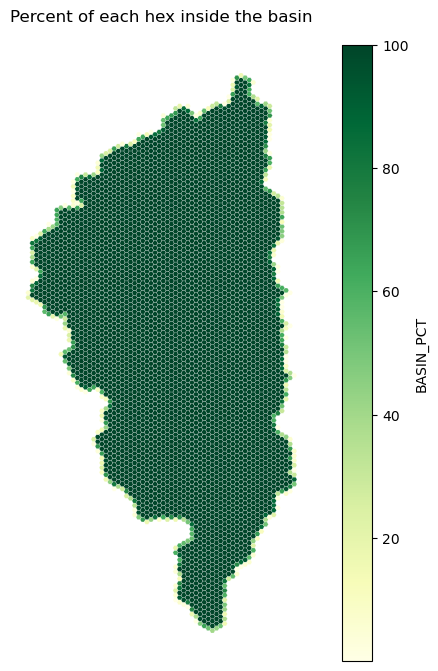

Exported c:\Users\amcclary\Documents\GitHub\ForestHealth\plot-network-design\outputs\vegetation_hexes.gpkg


In [64]:
RUN_EXAMPLE = True
EXPORT_GPKG = True
HEX_SIZE_HA = 30

if RUN_EXAMPLE:
    from IPython.display import display
    import matplotlib.pyplot as plt
    from matplotlib.collections import PolyCollection

    hex_fc, attribute_fields = build_hex_layer(HEX_SIZE_HA)
    print(f"Created {arcpy.management.GetCount(hex_fc)[0]} hexes at {HEX_SIZE_HA:g} ha each")
    print("Added fields:", attribute_fields)

    # geopandas' GDAL engines (pyogrio and fiona) both fail in this conda env with a
    # misleading WinError 206 from os.add_dll_directory when PATH is too long; read the
    # attributes and geometry directly with arcpy, which is already loaded and reliable.
    attr_fields = [f.name for f in arcpy.ListFields(hex_fc) if f.type not in ("OID", "Geometry")]
    table = pd.DataFrame(
        arcpy.da.SearchCursor(hex_fc, attr_fields), columns=attr_fields
    )
    display(table.head())
    print("\nSchema:\n", table.dtypes.to_string())
    display(table.select_dtypes(include="number").describe().T)

    polygons, basin_pct = [], []
    with arcpy.da.SearchCursor(hex_fc, ["SHAPE@", "BASIN_PCT"]) as rows:
        for shape, pct in rows:
            polygons.append(shape.getPart(0))
            basin_pct.append(pct)
    verts = [[(pt.X, pt.Y) for pt in ring if pt is not None] for ring in polygons]

    fig, ax = plt.subplots(figsize=(8, 8))
    collection = PolyCollection(verts, array=np.array(basin_pct), cmap="YlGn", linewidths=0.15, edgecolors="white")
    ax.add_collection(collection)
    ax.autoscale_view()
    ax.set_aspect("equal")
    fig.colorbar(collection, ax=ax, label="BASIN_PCT")
    ax.set_title("Percent of each hex inside the basin")
    ax.set_axis_off()
    plt.show()

    if EXPORT_GPKG:
        gpkg_path = export_hex_layer(hex_fc, FINAL_OUTPUT_DIR / "vegetation_hexes.gpkg")
        print(f"Exported {gpkg_path}")